# LeetCode #141: Linked List Cycle

https://leetcode.com/problems/linked-list-cycle/

## Two ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Remember every node (hash set)** | $O(n)$ | $O(n)$ | One walk down the list, but you keep a reference to every node you've stepped on — a 10,000-node list means a set holding 10,000 entries. |
| **Two pointers at different speeds ★** | $O(n)$ | $O(1)$ | The same single walk, and the memory is two variables no matter how long the list is. |

`n` is the number of nodes. $O(n)$ time means **"the work grows in step with the length of the
list"** — on the order of 10,000 pointer hops at this problem's limit. You can't do better, because a
loop can be wired in anywhere, so you have to walk far enough to reach it. $O(1)$ space means **"the
memory doesn't depend on the input"**; here it's two local variables, for 3 nodes or for 10,000.

## Understanding the methods

### Remember every node (hash set)

Walk the list, and put each node you stand on into a set. If you ever arrive at a node that is
already in the set, you have come back round to somewhere you've been, so there's a loop. If you
reach the end (`null`) first, there isn't one.

It's the easiest version to convince yourself is correct. The price is the set, which on a loop-free
list ends up holding every node. One detail matters: the set must hold the **nodes themselves**, not
their values — two different nodes may store the same number, so a set of values reports a loop on
the perfectly ordinary list `1 → 1`.

### Optimal: two pointers at different speeds ★

Put two walkers on the head of the list. Each turn, one moves forward a single node, the other moves
forward two. Then look at where they are.

If the list really ends, the fast walker gets there first and falls off — no loop. If it doesn't end,
both walkers are eventually inside the loop going round forever, and the fast one is gaining on the
slow one by exactly one node per turn. So the gap counts down one at a time: 3, 2, 1, 0. A gap that
shrinks by one can't skip past zero, so the fast walker has to land on the slow one exactly. That
collision is your proof.

This two-speed trick is called **Floyd's tortoise and hare**.

**Why this is the pick here:** both are a single pass, so the time is the same; the whole difference
is memory — a set that can grow to the length of the list, against two variables. Reach for the hash
set when you want the obviously-correct version, or when you need more than a yes/no answer (which
nodes are in the loop, say). Reach for the two pointers when memory matters, or when the interviewer
asks for constant space, which here they will.

**Constraints:**
* the list holds between 0 and 10,000 nodes
* `-10^5 <= Node.val <= 10^5`
* `pos` is `-1` for no loop, or the index the tail points back to — it only describes how the test
  input was built; your function is handed nothing but `head`


## Explain Like I'm a Newbie

### What the question is actually asking

You're handed the first node of a chain, each node pointing at the next. Normally it stops at a node
pointing at nothing — but the tail may have been wired back into the middle instead, in which case
following the pointers goes round forever. Say whether that happened. Not where.

```
3 -> 2 -> 0 -> -4
     ^           |
     +-----------+    the tail points back at 2, so: there is a loop
```

### The one idea you need: let a faster walker catch up

The real difficulty is that there's nothing to count down to. Walking a normal list you stop at
`null`; in a looped list `null` never arrives, so a plain walk never stops. It isn't wrong, it just
never finishes. You need a way to notice "I've been here before" — writing down every node you visit
does that, at the cost of memory proportional to the list.

The constant-space trick is **two** walkers from the head: each turn, one steps forward a node and
the other two. If the chain ends, the fast walker gets there first and falls off — no loop. If it
doesn't, both end up inside the loop and the fast one gains a node per turn, so the gap counts down
one at a time and passes *through* zero rather than over it. It lands on the slow walker exactly.

Two runners on a circular track, one quicker — and because the gap closes a node at a time, the lap
lands *on* a node rather than between two. The name for this is **Floyd's tortoise and hare**.

### What that means in code

Both start at `head`. Each turn: advance slow by one, fast by two, then compare. Three things have to
be right.

1. **Compare after the moves, not before.** Both start on the same node, so a check at the top of the
   loop reports "equal" immediately for every input, loop or not.
2. **The guard checks `fast` and `fast.next`.** Fast is about to take two steps, so the node it stands
   on *and* the one after it must exist.
3. **Compare node identity, not node values.** Two different nodes may hold the same number.

Falling out of the loop means fast met a `null`, and a `null` only exists if the chain has an end.

### Mistakes people make the first time

1. Guarding on `fast != null` alone, then crashing when `fast.next.next` runs on the last node.
2. Comparing before advancing, so every list looks looped.
3. Comparing values, not nodes — `1 -> 1` with no loop then reports one.
4. Making the hare take three steps "to be faster". The gap then closes by two per turn, so on an
   even-length loop entered at an odd gap it steps over the tortoise forever.
5. Reporting the meeting node as the start of the loop. It generally isn't.

### Things worth knowing

Nothing is modified, so the caller's chain survives — unlike the destructive shortcut of overwriting
each visited value with a sentinel.

Asked *where* the loop begins, the meeting point gets you there in one more phase: move one pointer
back to the head, leave the other where they met, then advance both a step at a time. They meet at
the entry.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show
you the problem to the moment the code is on the board.*

---

### The thirty-second version

Where you should end up: *"Two pointers from the head, one stepping a node at a time and one stepping
two. If the list ends, the fast one falls off and there's no loop. If there is one, both end up inside
it and the fast one closes the gap by exactly one node per step, so it lands on the slow one rather
than skipping past it. One pass, two variables."*

And then, unprompted: *"the weak spot is that the reason they must collide isn't obvious — it depends
on the step sizes being 1 and 2 — and the code is unforgiving about where the comparison goes."*

---

### I slide the problem across the table

I've handed you a linked list and asked whether it loops back on itself. Read it — thirty seconds of
quiet is fine — then give it back to me in your own words:

> **You:** "I've got the head of a singly linked list. Either it ends at a node whose `next` is null,
> or some node's `next` points back at an earlier node and there's no end at all; I return true in
> the second case. Two things to pin down — do you want *whether* there's a loop, or *where* it
> starts?"

A real question: finding the entry point is a longer algorithm that happens to build on this one.
I'll say **"just whether."**

> **You:** "And can I modify the list? I could mark nodes as visited by overwriting their values with
> something out of range."

Not a formality either — a genuine fork, and the destructive version is a real technique. I'll say
**"treat the list as read-only,"** which quietly removes a whole family of solutions and makes memory
the interesting question.

What I don't want is a recital. *"Can the head be null? Can the list be empty?"* — the constraints
say the list may have zero nodes, so you've read them back to me instead of thinking.

---

### Now tell me what's actually hard about it

If your first sentence is **"I'll use Floyd's tortoise and hare"**, I've learned almost nothing. It
might mean you understand the problem; it might mean you recognised the title. I can't tell, so I'll
spend ten minutes finding out.

> **You:** "The awkward thing is that the usual way to traverse a list doesn't terminate. I walk until
> `next` is null — but if there's a loop, null never shows up, so my loop runs forever. It's not that
> I'd get a wrong answer, I'd get no answer. So what I need is a way to detect that I've revisited a
> node."

Keep going:

> **You:** "The easy version puts every node I visit into a hash set and checks membership. One pass,
> works — but the set can end up holding every node. For constant space I need something cleverer:
> two pointers at different speeds. If the list ends, the faster one hits null and I'm done. If it
> doesn't, both get trapped in the loop, and the fast one gains on the slow one, so it must catch it."

Notice the order — difficulty, obvious fix, why the obvious fix isn't enough, and only then the
technique. From my chair that's completely different from producing the name first.

And if the hash set is all you get, say so and write it: a correct $O(n)$-space answer you can defend
beats a half-remembered two-pointer one you can't.

---

### Before you write it, convince me they actually meet

Here's where I'll push, because "the fast one catches up" is a hand-wave, and this is the rare problem
whose proof is short enough to say out loud:

> **You:** "Once both are inside the loop, take the distance from fast forward to slow, measured the
> way round the loop goes. Each step, slow advances one and fast advances two, so that distance drops
> by exactly one. A quantity that falls by one each step and can't go below zero has to *be* zero at
> some point — and zero means they're on the same node. They can't straddle it, because fast never
> gains two in a single step."

That's the whole argument, and it tells you something useful:

> **You:** "Which is why the speeds are 1 and 2. If fast moved three at a time the gap would shrink by
> two per step, and on an even-length loop entered at an odd gap it would step over slow forever."

Say that unprompted and we're having a conversation rather than an interview. Then the cost, derived:

> **You:** "Slow takes one step per iteration. Either it reaches the end of the list, at most n steps,
> or it enters the loop and meets fast within the loop's length — also bounded by n. So slow moves
> about n times at most and fast about 2n: $O(n)$. Space is two local pointers, $O(1)$, which is the
> actual reason to prefer this over the hash set."

---

### Now whiteboard it

```
slow = head
fast = head
while fast != null and fast.next != null:
    slow = slow.next
    fast = fast.next.next
    if slow == fast:
        return true
return false
```

As you write the `while` line, one sentence:

> **You:** "Two checks, because fast is about to take two hops — the node it's on and the node after
> it both have to exist before I dereference twice."

Skip it and I'll ask: *"walk me through `[1,2,3]` with no loop under a guard of just `fast != null`."*
On the second iteration `fast` sits on the `3`, which is non-null so the guard lets you in, and then
`fast.next.next` dereferences null and crashes. Every odd-length loop-free list does this, a single
node included.

As you write the comparison, **after** both moves:

> **You:** "The check goes at the bottom. Both pointers start on the head, so comparing first makes
> every list on earth come back true."

Skip that and I'll ask: *"what does your function return for a single node with no loop?"* It should
be false; the compare-first version returns true.

And the final `return false`:

> **You:** "Falling out means fast found a null, and a null only exists if the list has an end."

One thing I'd quietly notice either way: you compared the pointers, not `slow.val == fast.val`.

---

### Walk me through it before you say you're done

Don't hand back the pen and wait.

> **You:** "`[3,2,0,-4]` with the tail pointing back at the `2`. Both start on `3`. Turn one: slow on
> `2`, fast on `0` — not equal. Turn two: slow on `0`, fast goes `-4` then wraps to `2` — not equal.
> Turn three: slow on `-4`, fast goes `2`, `0`, `-4` — same node, true. Three turns."

Then the small inputs: an empty list leaves `fast` null so the loop never runs, false. One node with
no loop has `fast.next` null, false. Two nodes where the second points back at the first takes one
turn to put slow on the second and fast round onto the first, and a second turn to land them both on
the first — true.

> **You:** "And `[1,1]` with no loop returns false — the case I'd use to argue against remembering
> node *values* instead of identities. The values repeat; the nodes don't."

That callback to the clarifier is worth making.

---

### Tell me where it breaks, before I ask

> **You:** "Two honest caveats. First, this tells you a loop exists and nothing else — not its length,
> not where it starts, not which nodes are in it. For any of those I'd add a second phase from the
> meeting point, or just use the hash set, which hands you every visited node for free. Second, the
> proof depends on the steps being 1 and 2; if someone 'optimises' the hare to three later on, it
> silently stops detecting some loops. Worth a comment in the code."

I was going to ask about the first one, and you getting there first changes the tone of the rest of
the interview.

---

### What would worry me

- **Naming Floyd's in the first sentence** without explaining why a plain traversal fails. I can't
  tell memorisation from understanding, so I'll keep digging.
- **"The fast one laps the slow one"** offered as the proof. That's the conclusion; the argument is
  the gap shrinking by exactly one.
- **Calling the hash-set version $O(1)$ space** because "it's just a set". It holds up to n nodes.
- **Guarding on `fast` alone**, and not spotting it when I ask for an odd-length dry run.


## Solutions

All four follow the same three moves: advance the tortoise one node, advance the hare two, then ask
whether they are standing on the same node. The comments mark the two places the logic turns — the
loop guard, and the fact that the comparison comes *after* the moves.

### C#

`ListNode` is declared here for runnability; LeetCode supplies it. `==` on a `ListNode` compares
references rather than values, because the class doesn't overload it — and "same node?" is exactly
the question being asked.


In [ ]:
// Two walkers down the list: the tortoise one node per step, the hare two.
// O(n) time, O(1) space - the only memory is the two pointers.
public class ListNode {
    public int val;
    public ListNode next;
    public ListNode(int x) { val = x; next = null; }
}

public class Solution {
    public bool HasCycle(ListNode head) {
        var slow = head;   // tortoise: one node per step
        var fast = head;   // hare: two nodes per step

        // Both halves of the guard are needed. The hare is about to dereference
        // twice, so the node it stands on AND the node after it must exist.
        // Guarding on `fast != null` alone crashes inside fast.next.next on any
        // cycle-free list of odd length, a single node included.
        while (fast != null && fast.next != null) {
            slow = slow.next;
            fast = fast.next.next;

            // Compared AFTER both moves, never before: the two start on the same
            // node, so a check at the top of the loop reports a cycle for every
            // input. Meeting here means the hare closed a gap that shrinks by
            // exactly one node per step, so it landed on the tortoise rather
            // than stepping over it.
            if (slow == fast) return true;
        }

        // Falling out means the hare reached a null, and a null can only exist
        // if the list has an end.
        return false;
    }
}


### Python

`slow is fast` asks whether the two names point at the *same object*. `==` would start comparing
numbers the moment `ListNode` grew an `__eq__`, and two different nodes are allowed to hold the same
number.


In [ ]:
# Two walkers down the list: the tortoise one node per step, the hare two.
# O(n) time, O(1) space - the only memory is the two pointers.
class ListNode:
    def __init__(self, x):
        self.val = x
        self.next = None

class Solution:
    def hasCycle(self, head: 'Optional[ListNode]') -> bool:
        slow = fast = head   # tortoise one node per step, hare two

        # Both halves of the guard are needed. The hare is about to step twice,
        # so the node it stands on AND the node after it must exist. Guarding on
        # `fast` alone raises AttributeError inside fast.next.next on any
        # cycle-free list of odd length, a single node included.
        while fast and fast.next:
            slow = slow.next
            fast = fast.next.next

            # Compared AFTER both moves, never before: the two start on the same
            # node, so a check at the top of the loop reports a cycle for every
            # input. Meeting here means the hare closed a gap that shrinks by
            # exactly one node per step, so it landed on the tortoise rather
            # than stepping over it.
            if slow is fast:
                return True

        # Falling out means the hare reached a None, and a None can only exist
        # if the list has an end.
        return False


### Go

`slow == fast` on two `*ListNode` values compares the addresses they hold, so it is an identity test,
which is what this algorithm needs.


In [ ]:
// Two walkers down the list: the tortoise one node per step, the hare two.
// O(n) time, O(1) space - the only memory is the two pointers.
type ListNode struct {
    Val  int
    Next *ListNode
}

func hasCycle(head *ListNode) bool {
    slow, fast := head, head   // tortoise one node per step, hare two

    // Both halves of the guard are needed. The hare is about to dereference
    // twice, so the node it stands on AND the node after it must exist.
    // Guarding on `fast != nil` alone panics inside fast.Next.Next on any
    // cycle-free list of odd length, a single node included.
    for fast != nil && fast.Next != nil {
        slow = slow.Next
        fast = fast.Next.Next

        // Compared AFTER both moves, never before: the two start on the same
        // node, so a check at the top of the loop reports a cycle for every
        // input. Meeting here means the hare closed a gap that shrinks by
        // exactly one node per step, so it landed on the tortoise rather than
        // stepping over it.
        if slow == fast { return true }
    }

    // Falling out means the hare reached a nil, and a nil can only exist if
    // the list has an end.
    return false
}


### Rust

Rust's ownership rules won't let a chain of `Option<Box<ListNode>>` point back into itself, so a
cyclic list can't be built out of the safe node type at all — which is why this cell drops to raw
`*mut` pointers inside `unsafe`, where two pointers can be compared for identity. Read it as a sketch
of the idea rather than a submittable solution: the struct above still declares `next` as an
`Option<Box<ListNode>>`, not a raw pointer, so the pointer walk below does not line up with it. A
real Rust answer keeps the links as raw pointers (or `Rc<RefCell<…>>`) from end to end.


In [ ]:
// Floyd's Tortoise and Hare using raw pointers.
// Note: Rust's safe code doesn't allow cycles in ownership model;
// this uses unsafe raw pointer comparison for demonstration.
#[derive(Debug)]
pub struct ListNode {
    pub val: i32,
    pub next: Option<Box<ListNode>>,
}

// Cycle detection typically requires unsafe or Rc<RefCell<>> in Rust.
// Using raw pointer approach:
pub fn has_cycle(head: *mut ListNode) -> bool {
    unsafe {
        let (mut slow, mut fast) = (head, head);   // tortoise one node, hare two

        // Both halves of the guard are needed: the hare is about to dereference
        // twice, so the node it stands on AND the node after it must exist.
        while !fast.is_null() && !(*fast).next.is_null() {
            // map_or(null_mut(), ...) is how a missing link becomes a null
            // pointer here, so "walked off the end" and "null" are the same thing
            slow = (*slow).next.as_mut().map_or(std::ptr::null_mut(), |n| n.as_mut());
            let next1 = (*fast).next.as_mut().map_or(std::ptr::null_mut(), |n| n.as_mut());
            fast = (*next1).next.as_mut().map_or(std::ptr::null_mut(), |n| n.as_mut());

            // Compared AFTER both moves, never before: the two start on the same
            // node, so a check at the top of the loop reports a cycle for every
            // input. Raw-pointer `==` is address equality, which is the identity
            // test this algorithm needs.
            if slow == fast { return true; }
        }
        false
    }
}


## Example Scenarios

### 1. Common Case — cycle in the middle
**Input:** `head = [3,2,0,-4]`, `pos = 1`

The tail `-4` points back at index 1, the node holding `2`. Both pointers start on `3`; after three
turns the hare has gone round the loop and landed on the very node the tortoise is standing on
(`-4`), which is the proof $\Rightarrow$ **true**

### 2. Slightly Complex — two-node self-loop
**Input:** `head = [1,2]`, `pos = 0`

The second node points back at the first, so the whole list *is* the loop. One turn puts the tortoise
on `2` and sends the hare round onto `1`; the next turn lands them both on `1` $\Rightarrow$ **true**

### 3. Edge Case: Time Factor — single node, no cycle
**Input:** `head = [1]`, `pos = -1`

`fast.next` is already null, so the guard fails before the body runs once — the least work this
function can do. It is also the input that punishes a guard of `fast != null` alone, which would let
`fast.next.next` run and crash $\Rightarrow$ **false**

### 4. Edge Case: Space Factor — long acyclic list
**Input:** `head = [1,2,3,4,5]`, `pos = -1`

The hare goes $1 \to 3 \to 5$, and on the next check its `next` is null, so the walk stops after two
turns. However long the list gets, only two pointers are ever held — $O(1)$ — against one set entry
per node, $O(n)$, for the version that remembers where it has been $\Rightarrow$ **false**

### 5. Almost-Impossible but Plausible — empty list
**Input:** `head = []`, `pos = -1`

`head` is null, so `fast` is null, the guard's first test fails immediately, and nothing is ever
dereferenced. Zero nodes need no special case $\Rightarrow$ **false**


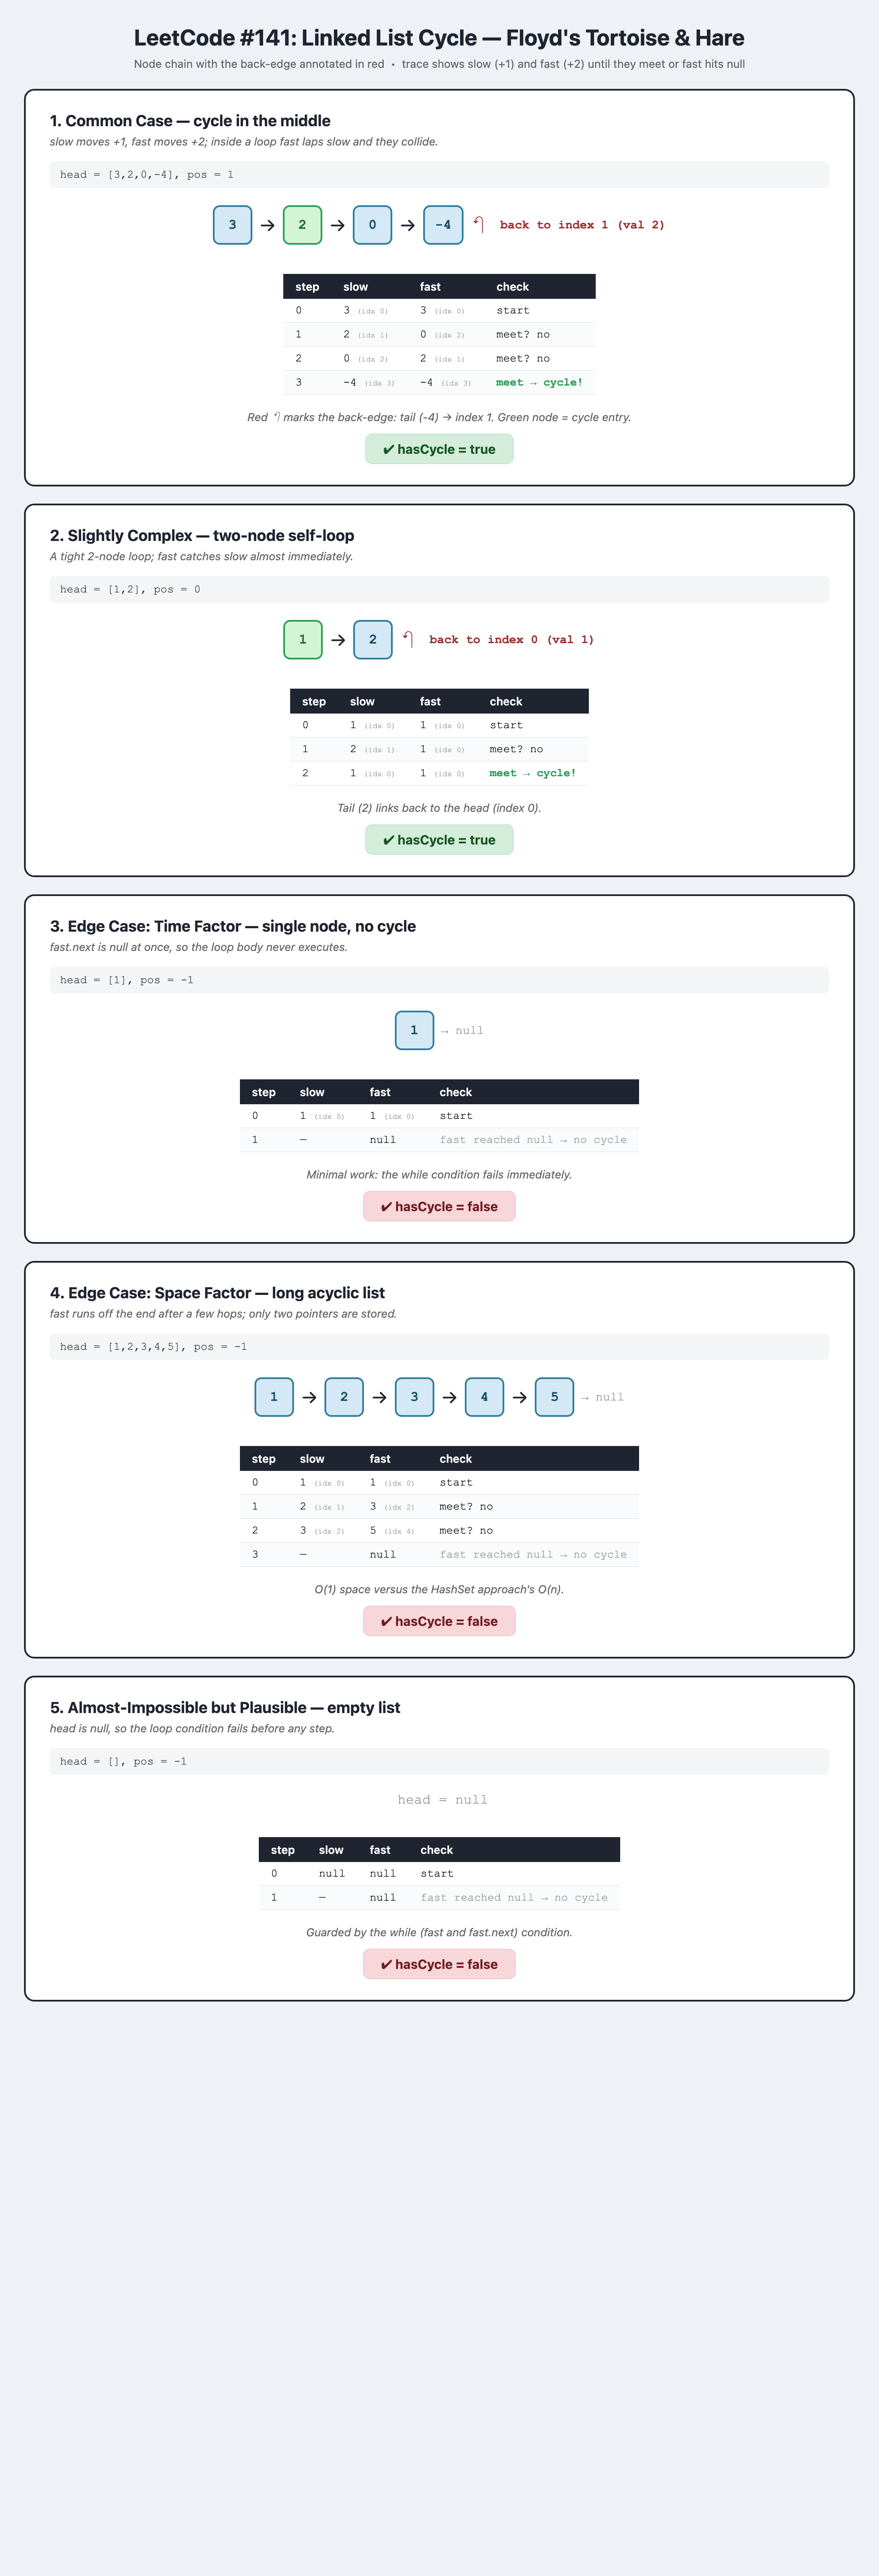